# 03 - Engagement and retention

Runs on fake data only (`npm run fake:load`). Analysing real users needs a privacy policy and anonymisation first (spec 04).

Three product questions, answered from the logged events and the wishlist:

1. **Do higher Taste Match scores get saved more?** Spec 03 section 7.2: save rate by fit bucket
   (0-40 / 40-70 / 70-100), separately for Home and Discover.
2. **Of titles saved, what share are watched within 30 days?** The saved-to-watched funnel.
3. **Do people come back?** Weekly active users by sign-up week (a cohort table).

Remember what generated this data: saves are drawn from the simulated user's *latent opinion* of
the title, **not** from the fit that was shown. So any link between fit and saving here exists only
because fit and latent opinion are correlated; it says nothing about whether *showing* a fit
changes what people do.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sqlalchemy as sa

from cinecircle_analysis import frames
from cinecircle_analysis.fakedata import FAKE_DOMAIN, FAKE_TMDB_BASE, START
from cinecircle_analysis.load import assert_local
from cinecircle_analysis.replay import BUCKETS, SURFACES, save_rate_by_bucket
from cinecircle_api.db import make_engine
from cinecircle_api.settings import Settings

engine = make_engine(Settings().database_url)
assert_local(engine)  # raises before any query unless the database is on this machine

FAKE = {"pattern": f"%@{FAKE_DOMAIN}", "base": FAKE_TMDB_BASE}  # the fake-only filters, as params
BLUE, ORANGE, GREY = "#3b6fb6", "#d9822b", "#8a8a8a"
SURFACE_COLOR = {"home": BLUE, "discover": ORANGE}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.figsize": (7, 4)})


def sql(query: str, **params) -> pd.DataFrame:
    """Run one hand-written, read-only query with the fake-only params always bound."""
    with engine.connect() as conn:
        return pd.read_sql_query(sa.text(query), conn, params={**FAKE, **params})


events = frames.events(engine)  # fake users' events only
print(pd.Series([e["event_type"] for e in events]).value_counts().to_string())

post_viewed        6141
post_created       3000
saved              1619
watched             501
discover_opened     221
onboarding_done      37


## 1. Save rate by fit bucket, per surface

A **view** is a `post_viewed` event on Home or each fit inside a `discover_opened` event on
Discover (ten titles per opening). A **save** counts on the surface it came from, in the bucket of
the fit it was saved with. The bars carry 95% Wilson intervals (a binomial interval that behaves
at small counts); the number under each bar is the number of views behind it.

saves  views save rate    ci low   ci high
surface  fit bucket                                            
home     0-40            0      0  no views  no views  no views
         40-70         284   2564     11.1%      9.9%     12.3%
         70-100        949   3577     26.5%     25.1%     28.0%
discover 0-40            0      0  no views  no views  no views
         40-70          49    841      5.8%      4.4%      7.6%
         70-100        333   1359     24.5%     22.3%     26.9%

lowest fit ever shown: Home 50, Discover 50 (so the 0-40 bucket is empty in this dataset)


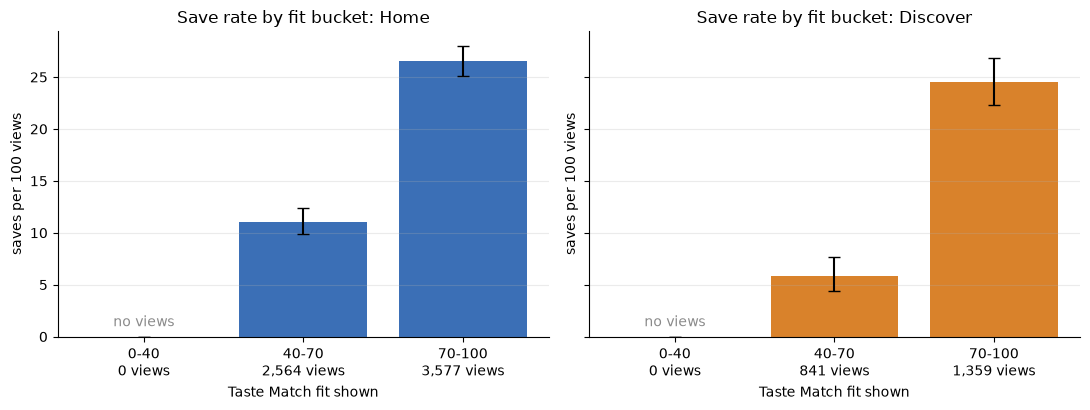

home: the top populated bucket is saved 2.4x as often as the lowest populated one (26.5% vs 11.1%)
discover: the top populated bucket is saved 4.2x as often as the lowest populated one (24.5% vs 5.8%)


In [2]:
rates = save_rate_by_bucket(events)


def wilson(saves, views, z=1.96):
    if views == 0:
        return float("nan"), float("nan")
    p = saves / views
    centre = (p + z * z / (2 * views)) / (1 + z * z / views)
    half = z * np.sqrt(p * (1 - p) / views + z * z / (4 * views**2)) / (1 + z * z / views)
    return centre - half, centre + half


table = pd.DataFrame([
    {"surface": s, "fit bucket": b, "saves": sv, "views": v, "save rate": sv / v if v else np.nan,
     "ci low": wilson(sv, v)[0], "ci high": wilson(sv, v)[1]}
    for s in SURFACES for b, (sv, v) in rates[s].items()
])
shown = table.set_index(["surface", "fit bucket"]).copy()
for col in ("save rate", "ci low", "ci high"):
    shown[col] = shown[col].map(lambda x: "no views" if np.isnan(x) else f"{100 * x:.1f}%")
display(shown)

home_fits = [e["props"]["fit"] for e in events
             if e["event_type"] == "post_viewed" and e["props"].get("fit") is not None]
discover_fits = [f for e in events if e["event_type"] == "discover_opened"
                 for f in e["props"].get("fits", [])]
print(f"lowest fit ever shown: Home {min(home_fits)}, Discover {min(discover_fits)} "
      f"(so the 0-40 bucket is empty in this dataset)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, surface in zip(axes, SURFACES):
    part = table[table.surface == surface].reset_index(drop=True)
    rate = 100 * part["save rate"].fillna(0)
    err = [(rate - 100 * part["ci low"]).fillna(0), (100 * part["ci high"] - rate).fillna(0)]
    ax.bar(range(3), rate, yerr=err, capsize=4, color=SURFACE_COLOR[surface])
    ax.set_xticks(range(3), [f"{b}\n{v:,} views" for b, v in zip(part["fit bucket"], part.views)])
    ax.set(title=f"Save rate by fit bucket: {surface.title()}", xlabel="Taste Match fit shown",
           ylabel="saves per 100 views")
    ax.grid(axis="x", alpha=0)
    for k, v in enumerate(part.views):
        if v == 0:
            ax.text(k, 1, "no views", ha="center", color=GREY)
fig.tight_layout()
plt.show()

for surface in SURFACES:
    seen = table[(table.surface == surface) & (table.views > 0)]["save rate"]
    print(f"{surface}: the top populated bucket is saved {seen.iloc[-1] / seen.iloc[0]:.1f}x as "
          f"often as the lowest populated one ({100 * seen.iloc[-1]:.1f}% vs "
          f"{100 * seen.iloc[0]:.1f}%)")

## 2. The saved-to-watched funnel (30 days)

Spec 04 phase-4 question: *of titles saved, what percentage were watched within 30 days?* A saved
title counts as watched when the user rated it later (`status = 'watched'`, `watched_at` set).

One trap: a title saved in the last 30 days of the data has not had its full window yet, so it
cannot be counted as "not watched". The query only keeps saves made at least 30 days before the
last event (the horizon), and the `ROLLUP` row is the total over both sources.

data horizon (last fake event): 2026-11-01


,saved,watched_ever,watched_30d,share watched within 30 days
source,,,,
discover,328,149,100,30.5%
post,1124,346,233,20.7%
all,1452,495,333,22.9%


left out because their 30 days were not over yet: 167 saves


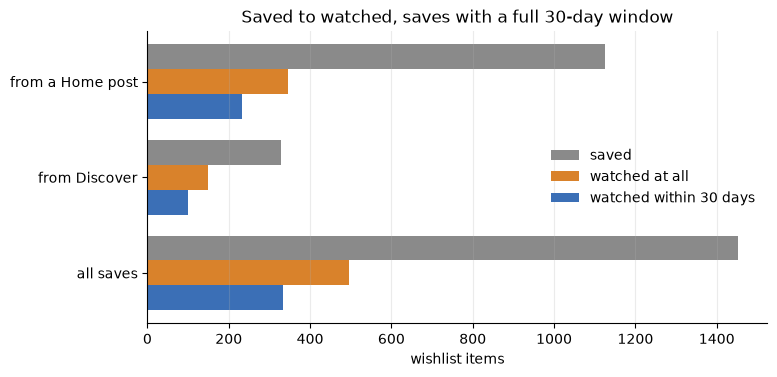

In [3]:
horizon = max(e["created_at"] for e in events)
print("data horizon (last fake event):", horizon.date())

funnel = sql("""
    SELECT COALESCE(w.source, 'all') AS source,
           count(*) AS saved,
           count(*) FILTER (WHERE w.status = 'watched') AS watched_ever,
           count(*) FILTER (WHERE w.status = 'watched'
                              AND w.watched_at <= w.added_at + interval '30 days') AS watched_30d
    FROM app.wishlist_items w
    JOIN auth.users u ON u.id = w.owner_id AND u.email LIKE :pattern
    JOIN app.titles t ON t.id = w.title_id AND t.tmdb_id >= :base
    WHERE w.added_at <= CAST(:horizon AS timestamptz) - interval '30 days'
    GROUP BY ROLLUP (w.source)
    ORDER BY (w.source IS NULL), w.source
""", horizon=horizon).set_index("source")
funnel["share watched within 30 days"] = (
    (100 * funnel.watched_30d / funnel.saved).round(1).astype(str) + "%")
display(funnel)

censored = sql("""
    SELECT count(*) AS saved_too_recently
    FROM app.wishlist_items w
    JOIN auth.users u ON u.id = w.owner_id AND u.email LIKE :pattern
    JOIN app.titles t ON t.id = w.title_id AND t.tmdb_id >= :base
    WHERE w.added_at > CAST(:horizon AS timestamptz) - interval '30 days'
""", horizon=horizon).iloc[0, 0]
print(f"left out because their 30 days were not over yet: {censored} saves")

fig, ax = plt.subplots(figsize=(8, 3.8))
order = ["post", "discover", "all"]
width = 0.26
for k, (label, column, color) in enumerate([("saved", "saved", GREY),
                                            ("watched at all", "watched_ever", ORANGE),
                                            ("watched within 30 days", "watched_30d", BLUE)]):
    ax.barh(np.arange(3) + (k - 1) * width, funnel.loc[order, column], height=width,
            color=color, label=label)
ax.set_yticks(range(3), ["from a Home post", "from Discover", "all saves"])
ax.invert_yaxis()
ax.set(title="Saved to watched, saves with a full 30-day window", xlabel="wishlist items")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0)
plt.show()

Does the fit at the time of saving predict whether the title was then watched? Same cohort,
bucketed by `fit_at_save` (saves made while the user was still locked have no fit and are left out):

In [4]:
wish = pd.DataFrame(frames.wishlist(engine))
wish = wish[wish.added_at <= horizon - pd.Timedelta(days=30)].copy()
wish["watched_30d"] = ((wish.status == "watched")
                       & (wish.watched_at <= wish.added_at + pd.Timedelta(days=30)))
assert wish.watched_30d.sum() == funnel.loc["all", "watched_30d"]  # pandas agrees with the SQL
assert len(wish) == funnel.loc["all", "saved"]

with_fit = wish[wish.fit_at_save.notna()].copy()
with_fit["fit bucket"] = pd.cut(with_fit.fit_at_save, [-1, 39.999, 69.999, 100], labels=BUCKETS)
by_fit = with_fit.groupby("fit bucket", observed=True).watched_30d.agg(["sum", "size", "mean"])
by_fit.columns = ["watched within 30 days", "saved", "share"]
by_fit["share"] = (100 * by_fit.share).round(1).astype(str) + "%"
display(by_fit[["saved", "watched within 30 days", "share"]])

,saved,watched within 30 days,share
fit bucket,,,
40-70,288,56,19.4%
70-100,1160,276,23.8%


## 3. Weekly active users by sign-up week

Weeks are counted from the timeline's Monday start; a user's **cohort** is the week they signed
up. The SQL returns one row per (cohort, calendar week) of distinct active users; pandas turns it
into the usual triangle (rows are cohorts, columns are weeks since sign-up, cells are the share of
the cohort active that week). The final, partial week of data is left out.

*Active* is defined two ways, because the first turns out to say little here:

- **Any logged activity** (the spec's definition): a post created, a post viewed, a title saved or
  Discover opened.
- **Own actions only:** the same without post views. In this generator a view happens whenever a
  followee shares a rating (a follower views it with probability 0.6), whether or not the follower
  has drifted away, so views are driven by other people's activity, not the viewer's.

In [5]:
ACTIVITY = {
    "any logged activity": ("post_created", "post_viewed", "saved", "discover_opened"),
    "own actions only": ("post_created", "saved", "discover_opened"),
}
WEEK = "CAST(floor(extract(epoch FROM ({col} - CAST(:start AS timestamptz))) / 604800) AS integer)"

cohort_size = sql(f"""
    SELECT {WEEK.format(col="p.created_at")} AS cohort, count(*) AS users
    FROM auth.users u JOIN app.profiles p ON p.id = u.id
    WHERE u.email LIKE :pattern
    GROUP BY 1 ORDER BY 1
""", start=START).set_index("cohort").users
last_full_week = int((horizon - pd.Timestamp(START)).days // 7) - 1  # drop the partial last week


def weekly_activity(event_types):
    """One row per (sign-up cohort, calendar week): distinct active users. Plain SQL, fake-only."""
    return sql(f"""
        WITH fu AS (
            SELECT u.id, {WEEK.format(col="p.created_at")} AS cohort
            FROM auth.users u JOIN app.profiles p ON p.id = u.id
            WHERE u.email LIKE :pattern),
        active AS (
            SELECT DISTINCT e.user_id, {WEEK.format(col="e.created_at")} AS week
            FROM app.events e JOIN fu ON fu.id = e.user_id
            WHERE e.event_type = ANY(:types))
        SELECT fu.cohort, a.week, a.week - fu.cohort AS weeks_since_signup,
               count(*) AS active_users
        FROM active a JOIN fu ON fu.id = a.user_id
        GROUP BY fu.cohort, a.week
        ORDER BY fu.cohort, a.week
    """, start=START, types=list(event_types))


def triangle(event_types):
    activity = weekly_activity(event_types)
    activity = activity[activity.week <= last_full_week]
    counts = activity.pivot(index="cohort", columns="weeks_since_signup", values="active_users")
    counts = counts.reindex(cohort_size.index).fillna(0)
    share = counts.div(cohort_size, axis=0) * 100
    for cohort in share.index:  # beyond the last full week is unobserved, not zero
        share.loc[cohort, [w for w in share.columns if cohort + w > last_full_week]] = np.nan
    observed = counts.where(share.notna())
    denominator = observed.notna().mul(cohort_size, axis=0).sum()  # cohort sizes, observed cells
    retention = (observed.sum() / denominator * 100).dropna()
    return share, retention, activity.groupby("week").active_users.sum()


results = {name: triangle(types) for name, types in ACTIVITY.items()}
print("cohort sizes (users who signed up in each week):", cohort_size.to_dict())
print(f"total fake users: {cohort_size.sum()}; last full week used: {last_full_week}")

# the SQL and a pandas recount from the same events agree
recount = (
    pd.DataFrame(events)
    .assign(week=lambda d: (d.created_at - pd.Timestamp(START)).dt.days // 7)
    .query("event_type in @ACTIVITY['any logged activity'] and week <= @last_full_week")
    .groupby("week").user.nunique()
)
assert (recount.values == results["any logged activity"][2].values).all()

cohort sizes (users who signed up in each week): {0: 9, 1: 6, 2: 9, 3: 2, 4: 4, 5: 2, 6: 3, 7: 3, 8: 2, 9: 3, 10: 1, 11: 1, 12: 5}
total fake users: 50; last full week used: 24


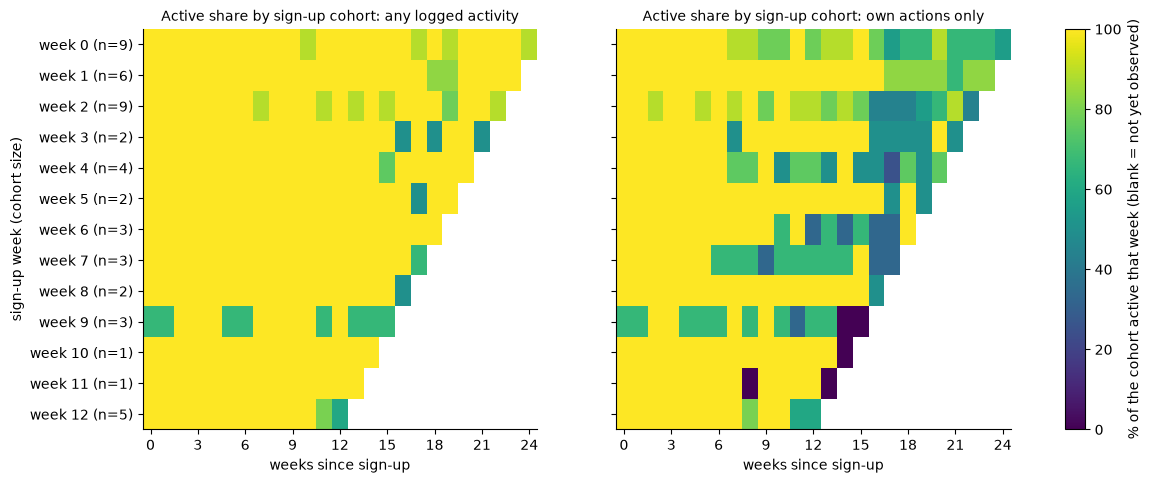

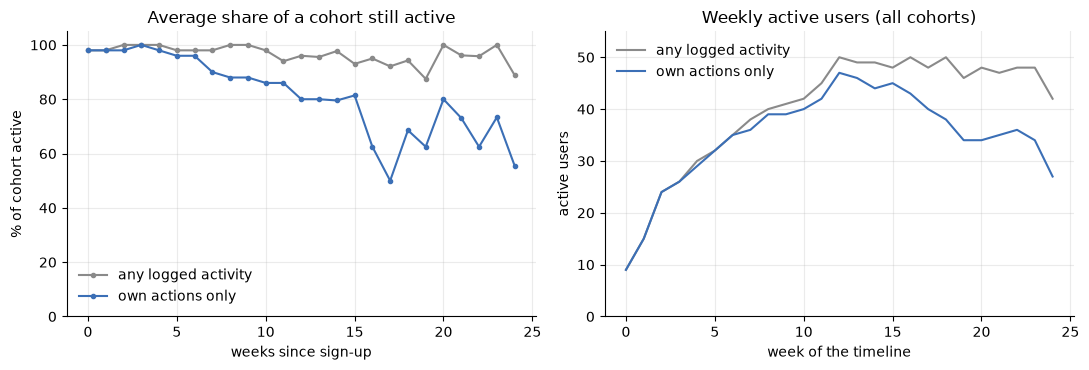

weeks since sign-up,0,1,2,4,8,12,16,20
% of cohort active,,,,,,,,
any logged activity,98.0,98.0,100.0,100.0,100.0,96.0,95.0,100.0
own actions only,98.0,98.0,98.0,98.0,88.0,80.0,62.0,80.0


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
for ax, (name, (share, _, _)) in zip(axes, results.items()):
    image = ax.imshow(share.values, aspect="auto", cmap="viridis", vmin=0, vmax=100)
    ax.set_xticks(range(0, len(share.columns), 3), list(share.columns[::3]))
    ax.set(title=f"Active share by sign-up cohort: {name}", xlabel="weeks since sign-up")
    ax.title.set_fontsize(10)
    ax.grid(False)
axes[0].set_yticks(range(len(cohort_size)),
                   [f"week {c} (n={n})" for c, n in cohort_size.items()])
axes[0].set_ylabel("sign-up week (cohort size)")
fig.colorbar(image, ax=axes, label="% of the cohort active that week (blank = not yet observed)")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for (name, (_, retention, wau)), color in zip(results.items(), (GREY, BLUE)):
    axes[0].plot(retention.index, retention.values, marker="o", markersize=3, color=color,
                 label=name)
    axes[1].plot(wau.index, wau.values, color=color, label=name)
axes[0].set(title="Average share of a cohort still active", xlabel="weeks since sign-up",
            ylabel="% of cohort active", ylim=(0, 105))
axes[1].set(title="Weekly active users (all cohorts)", xlabel="week of the timeline",
            ylabel="active users", ylim=(0, 55))
for ax in axes:
    ax.legend(frameon=False)
fig.tight_layout()
plt.show()

summary = pd.DataFrame({name: retention.reindex([0, 1, 2, 4, 8, 12, 16, 20]).round(0)
                        for name, (_, retention, _) in results.items()})
summary.index.name = "weeks since sign-up"
display(summary.T.rename_axis("% of cohort active"))

## 4. Findings, and what this does and does not show

**What the outputs above show (seed 7).**

- **Higher fit gets saved more, on both surfaces.** Home: 11.1% of views in the 40-70 bucket end in
  a save against 26.5% in 70-100 (2.4x). Discover: 5.8% against 24.5% (4.2x). The 95% intervals do
  not overlap. **The 0-40 bucket is empty:** the lowest fit ever shown was 50, so only two of the
  three buckets carry data and "40-70" really means 50-70. If real data looked like this, the
  bucket edges in spec 03 section 7.2 would need to move up to separate anything.
- **Saved to watched in 30 days:** of 1,452 saves with a full 30-day window, 495 (34%) were watched
  at some point and 333 (22.9%) within 30 days; 167 later saves were left out because their window
  was not over. Saves from Discover were watched more often (30.5%) than saves from Home posts
  (20.7%). By fit at save, 19.4% (40-70) against 23.8% (70-100): a smaller gap than for saving
  itself.
- **Retention depends entirely on what counts as active.** With any logged activity (including
  views) the average cohort is 95-100% active in every week sampled, which tells us nothing. Counting only
  the user's own actions (posting, saving, opening Discover) gives a curve that falls from 98% in
  the first weeks to 88% at week 8, 80% at week 12 and 62% at week 16 (80% at week 20, from only the
  earliest cohorts, so noisy). Cohorts are small (1 to 9 users), so single cells jump around.

**What it cannot show.**

- Saves in the generator come from the simulated user's latent opinion, not from the fit shown, so
  the fit-to-save link is correlation through that shared cause and is **not** a measurement of
  what showing a Taste Match percentage does to behaviour. A real answer would need an experiment
  (some users shown the fit, some not).
- The shapes of the funnel and of retention are the generator's settings (a saved title gets a large
  boost in the chance it is rated next; activity decays with a personal half-life), read back through
  SQL. The point of the notebook is the queries and the cautions (right-censoring the 30-day
  window, choosing an activity definition that can move), not the percentages.
- 50 invented users: nothing here is a statement about real users.